<a href="https://colab.research.google.com/github/do-alisa/final-data-analysis-project/blob/main/Spotify_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Milestone 0**


### Loading the Spotify Dataset

In [ ]:
# Install KaggleHub
!pip -q install kagglehub

import kagglehub
import pandas as pd
import numpy as np
import os
import glob

# Download dataset from Kaggle
dataset_path = kagglehub.dataset_download(
    "yashdev01/spotify-tracks-dataset"
)

print("Dataset location:", dataset_path)

# Find CSV files
csv_files = glob.glob(dataset_path + "/**/*.csv", recursive=True)
print(csv_files)

# Load the first CSV file
df = pd.read_csv(csv_files[0])

print("Dataset successfully loaded!")

Using Colab cache for faster access to the 'spotify-tracks-dataset' dataset.
Dataset location: /kaggle/input/spotify-tracks-dataset
['/kaggle/input/spotify-tracks-dataset/spotify-tracks-dataset.csv']
Dataset successfully loaded!


### Choose a Dataset

**DATASET**: Spotify Tracks Dataset

**SOURCE**: https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

**DESCRIPTION**:
A collection of Spotify tracks containing information about artists, albums,
song characteristics, popularity, and genre classifications. The dataset
can be used to analyze which musical features are associated with track
popularity.

**DATA DICTIONARY**:

- track_id: Unique identifier for each track
- artists: Artist or artists who performed the track
- album_name: Name of the album containing the track
- track_name: Name of the song
- popularity: Spotify popularity score from 0 to 100
- duration_ms: Track duration in milliseconds
- explicit: Indicates whether the track contains explicit content
- danceability: How suitable the track is for dancing, from 0 to 1
- energy: Intensity and activity level of the track, from 0 to 1
- key: Musical key of the track, represented by an integer from -1 to 11
- loudness: Overall loudness of the track measured in decibels
- mode: Musical modality; 1 represents major and 0 represents minor
- speechiness: Amount of spoken words in the track, from 0 to 1
- acousticness: Confidence that the track is acoustic, from 0 to 1
- instrumentalness: Likelihood that the track contains no vocals, from 0 to 1
- liveness: Likelihood that the track was recorded during a live performance, from 0 to 1
- valence: Musical positivity or happiness of the track, from 0 to 1
- tempo: Estimated tempo of the track in beats per minute
- time_signature: Estimated number of beats in each measure
- track_genre: Genre associated with the track

### Initial Quality Audit

In [ ]:
# Remove unnecessary index columns before the audit
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"], errors="ignore")

print("INITIAL QUALITY AUDIT")
print("---------------------")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\nNote: Originally, there were 22 columns. The columns Unnamed: 0.1 and Unnamed: 0 were excluded from the data \ndictionary because they were unnecessary index columns created during file export.")


print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values:")
missing = df.isnull().sum()
missing = missing[missing > 0]

if len(missing) == 0:
    print("No missing values")
else:
    for column, count in missing.items():
        percentage = count / len(df) * 100
        print(f"- {column}: {count:,} missing ({percentage:.2f}%)")

print("\nDuplicates:")
print(f"- Exact duplicate rows: {df.duplicated().sum():,}")

# Number of repeated duplicate rows
repeated_track_rows = df["track_id"].duplicated().sum()

# Number of unique track IDs that appear more than once
repeated_track_ids = (
    df["track_id"].value_counts().gt(1).sum()
)

print(f"- Repeated track rows: {repeated_track_rows:,}")
print(f"- Unique track IDs appearing multiple times: {repeated_track_ids:,}")
print(f"- Unique track IDs: {df['track_id'].nunique():,}")


print("\nClarification on Repeated Track IDs:")
print("The dataset contains 24,259 repeated track IDs. These were not automatically removed because \nthe repeated rows may contain different genre labels for the same song. \nThe rows were retained for genre analysis, while one row per track was used for track-level \nstatistical analysis.")

print("\nPotential problems:")
print("- Some tracks appear under multiple genre labels.")
print("- Exact duplicate rows should be removed.")
print("- Numeric columns should be checked for unusual or invalid values.")

# Show example repeated tracks
print("\nExamples of tracks with multiple genre labels:")

display(
    df[df["track_id"].duplicated(keep=False)]
    [["track_id", "track_name", "artists", "track_genre"]]
    .sort_values("track_id")
    .head(10)
)

INITIAL QUALITY AUDIT
---------------------
Rows: 114,000
Columns: 20

Note: Originally, there were 22 columns. The columns Unnamed: 0.1 and Unnamed: 0 were excluded from the data 
dictionary because they were unnecessary index columns created during file export.

Column names:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Data types:
float64    9
object     5
int64      5
bool       1
Name: count, dtype: int64

Missing values:
- artists: 1 missing (0.00%)
- album_name: 1 missing (0.00%)
- track_name: 1 missing (0.00%)

Duplicates:
- Exact duplicate rows: 450
- Repeated track rows: 24,259
- Unique track IDs appearing multiple times: 16,641
- Unique track IDs: 89,741

Clarification on Repeated Track IDs:
The dataset contains 24,259 repeated track IDs. These were not automat

,track_id,track_name,artists,track_genre
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,chill
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,soul
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,punk-rock
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,ska
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,rock
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alternative
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alt-rock
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,emo
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,sad
97533,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,sertanejo


# **Milestone 1**

### Clean the Data

In [ ]:
# Create a separate cleaned dataframe
df_clean = df.copy()

print("Rows before cleaning:", len(df_clean))

# Remove exact duplicate rows
exact_duplicates = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

print("Exact duplicate rows removed:", exact_duplicates)
print("Rows after removing exact duplicates:", len(df_clean))

Rows before cleaning: 114000
Exact duplicate rows removed: 450
Rows after removing exact duplicates: 113550


**Cleaning Decision #1:**
* After removing the unnecessary index columns, 450 rows were completely identical.
* These rows were removed because they did not provide any additional information.

In [ ]:
missing_track_rows = df_clean[
    df_clean[["artists", "album_name", "track_name"]]
    .isnull()
    .any(axis=1)
]

display(missing_track_rows)

df_clean = df_clean.dropna(
    subset=["artists", "album_name", "track_name"]
).copy()

print("Rows after removing missing information:", len(df_clean))
print("Missing values remaining:", df_clean.isnull().sum().sum())

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


Rows after removing missing information: 113549
Missing values remaining: 0


**Cleaning Decision #2:**
* One row was missing the artists, album_name, and track_name values. It also had a duration of 0 milliseconds and a popularity score of 0.
* Since these fields are essential for identifying a track, the row was removed instead of being imputed.

In [ ]:
zero_tempo_count = (df_clean["tempo"] == 0).sum()

zero_time_signature_count = (
    df_clean["time_signature"] == 0
).sum()

print("Tempo values equal to 0:", zero_tempo_count)
print(
    "Time signature values equal to 0:",
    zero_time_signature_count
)

# The zero values are kept because replacing them could create
# inaccurate musical information. They will only be excluded
# temporarily when calculating related statistics.

Tempo values equal to 0: 157
Time signature values equal to 0: 163


**Cleaning Decision #3:**
* Some tracks had a tempo or time signature of 0.
* These values were kept because replacing them with estimated values could create inaccurate musical information.
* When calculating tempo-related statistics, zero values were treated as unknown.

In [ ]:

# Convert duration from milliseconds to minutes
df_clean["duration_min"] = (
    df_clean["duration_ms"] / 60000
).round(2)

**Cleaning Decision #4:**
* The original duration_ms column was kept, and a new duration_min column was created by converting milliseconds into minutes.
* This made the track durations easier to interpret.

In [ ]:
print("\nFINAL CLEANED DATASET CHECK")
print("---------------------------")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))
print(
    "Missing values:",
    df_clean.isnull().sum().sum()
)
print(
    "Exact duplicate rows:",
    df_clean.duplicated().sum()
)
print(
    "Unique track IDs:",
    df_clean["track_id"].nunique()
)

print("\nMissing values by column:")
display(df_clean.isnull().sum())


FINAL CLEANED DATASET CHECK
---------------------------
Rows: 113549
Columns: 21
Missing values: 0
Exact duplicate rows: 0
Unique track IDs: 89740

Missing values by column:


,0
track_id,0
artists,0
album_name,0
track_name,0
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0


### Descriptive Statistics

In [ ]:
descriptive_columns = [
    "popularity",
    "duration_min",
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

# Create a temporary copy so tempo = 0 is treated as unknown
descriptive_data = df_clean[descriptive_columns].copy()

descriptive_data["tempo"] = descriptive_data["tempo"].replace(
    0, np.nan
)

descriptive_statistics = descriptive_data.describe().T

print("DESCRIPTIVE STATISTICS")
print("----------------------")

display(descriptive_statistics.round(2))

print("\nThe descriptive statistics shows:\n- the average track has a popularity score of 33.32 \n- an average duration of 3.80 minutes \n- danceability of 0.57 \n- energy of 0.64 \n- The median track duration is 3.55 minutes")
print("\nTempo has fewer observations because tempo values of 0 were treated as unknown \nrather than actual tempos. The maximum duration of 87.29 minutes was identified as \na potential outlier. We need to conduct further analysis to see how many possible \noutliers there are.")

DESCRIPTIVE STATISTICS
----------------------


,count,mean,std,min,25%,50%,75%,max
popularity,113549.0,33.32,22.28,0.00,17.00,35.00,50.00,100.00
duration_min,113549.0,3.80,1.77,0.14,2.90,3.55,4.36,87.29
danceability,113549.0,0.57,0.17,0.00,0.46,0.58,0.70,0.98
energy,113549.0,0.64,0.25,0.00,0.47,0.68,0.85,1.00
acousticness,113549.0,0.31,0.33,0.00,0.02,0.17,0.60,1.00
instrumentalness,113549.0,0.16,0.31,0.00,0.00,0.00,0.05,1.00
liveness,113549.0,0.21,0.19,0.00,0.10,0.13,0.27,1.00
valence,113549.0,0.47,0.26,0.00,0.26,0.46,0.68,1.00
tempo,113392.0,122.34,29.65,30.20,99.51,122.03,140.08,243.37



The descriptive statistics shows:
- the average track has a popularity score of 33.32 
- an average duration of 3.80 minutes 
- danceability of 0.57 
- energy of 0.64 
- The median track duration is 3.55 minutes

Tempo has fewer observations because tempo values of 0 were treated as unknown 
rather than actual tempos. The maximum duration of 87.29 minutes was identified as 
a potential outlier. We need to conduct further analysis to see how many possible 
outliers there are.


In [ ]:
duration = df_clean["duration_min"]

Q1 = duration.quantile(0.25)
Q3 = duration.quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier boundary:", upper_bound)

long_tracks = df_clean[
    df_clean["duration_min"] > upper_bound
].sort_values("duration_min", ascending=False)

print("Potential duration outliers:", len(long_tracks))
print(
    "Percentage:",
    round(len(long_tracks) / len(df_clean) * 100, 2),
    "%"
)

display(
    long_tracks[
        ["artists", "track_name", "duration_min", "track_genre"]
    ].head(10)
)

Q1: 2.9
Q3: 4.36
IQR: 1.4600000000000004
Upper outlier boundary: 6.550000000000001
Potential duration outliers: 5282
Percentage: 4.65 %


,artists,track_name,duration_min,track_genre
73617,Tale Of Us,Unity (Voyage Mix) Pt. 1,87.29,minimal-techno
10935,Timo Maas,Crossing Wires 002 - Continuous DJ Mix,79.82,breakbeat
24348,Seth Troxler,The Lab 03 - Continuous DJ Mix Part 1,78.84,detroit-techno
73840,Loco Dice,Amnesia Ibiza Underground 10 DJ Mix,76.06,minimal-techno
13344,Mark Farina,House of Om - Mark Farina - Continuous Mix,74.13,chicago-house
13245,Mark Farina,Live In Tokyo - Continuous Mix,72.33,chicago-house
13195,Mark Farina,Greenhouse Construction,72.25,chicago-house
27926,Lenzman;Dan Stezo,"NQ State of Mind, Vol. 1 - Continuous DJ Mix",70.77,drum-and-bass
101390,Ocean Sounds,Ocean Waves Sounds,68.67,sleep
45900,Estas Tonne,Internal Flight,64.60,guitar



The IQR method identified 5,282 potential duration outliers, representing
4.65% of the dataset. These tracks were retained because they may represent
legitimate extended recordings rather than data-entry errors. Because the
duration distribution is right-skewed, the median and quartiles were used
alongside the mean to describe typical track length.



The IQR method identified 5,282 potential duration outliers, representing
4.65% of the dataset. These tracks were retained because they may represent
legitimate extended recordings rather than data-entry errors. Because the
duration distribution is right-skewed, the median and quartiles were used
alongside the mean to describe typical track length.

### Two-Sample T-Test

We used a two-sample t-test to compare the average popularity of explicit and non-explicit songs.

* Null hypothesis: There is no difference in average popularity between explicit and non-explicit songs.
* Alternative hypothesis: There is a difference in average popularity between explicit and non-explicit songs.

In [ ]:
from scipy import stats

# Use one row per unique track
unique_tracks = df_clean.drop_duplicates(
    subset="track_id"
)

# Separate popularity scores
explicit_tracks = unique_tracks[
    unique_tracks["explicit"] == True
]["popularity"]

nonexplicit_tracks = unique_tracks[
    unique_tracks["explicit"] == False
]["popularity"]

# Perform Welch's two-sample t-test
t_statistic, p_value = stats.ttest_ind(
    explicit_tracks,
    nonexplicit_tracks,
    equal_var=False
)

print("TWO-SAMPLE T-TEST")
print("-----------------")
print("Null hypothesis: There is no difference in average popularity between explicit and non-explicit songs.")
print("Alternative hypothesis: There is a difference in average popularity between explicit and non-explicit songs.")

print(f"\nExplicit songs average popularity: {explicit_tracks.mean():.2f}")
print(f"Non-explicit songs average popularity: {nonexplicit_tracks.mean():.2f}")
print(f"t-statistic: {t_statistic:.3f}")
print(f"p-value: {p_value:.5e}")

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is a statistically significant difference in average popularity.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is not enough evidence of a statistically significant difference.")

TWO-SAMPLE T-TEST
-----------------
Null hypothesis: There is no difference in average popularity between explicit and non-explicit songs.
Alternative hypothesis: There is a difference in average popularity between explicit and non-explicit songs.

Explicit songs average popularity: 36.89
Non-explicit songs average popularity: 32.85
t-statistic: 15.252
p-value: 7.10903e-52

Conclusion: Reject the null hypothesis.
There is a statistically significant difference in average popularity.


# **Milestone 2**

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# Colorblind-friendly styling
sns.set_theme(style="whitegrid", palette="colorblind")

# Use one row per track for track-level charts
unique_tracks = df_clean.drop_duplicates(
    subset="track_id"
).copy()

# Use a temporary dataframe for analysis
plot_data = unique_tracks.copy()

# Treat tempo = 0 as unknown
plot_data["tempo"] = plot_data["tempo"].replace(0, np.nan)

# Store figures for the PDF file
figures = []

### Visualization 1: Popularity distribution

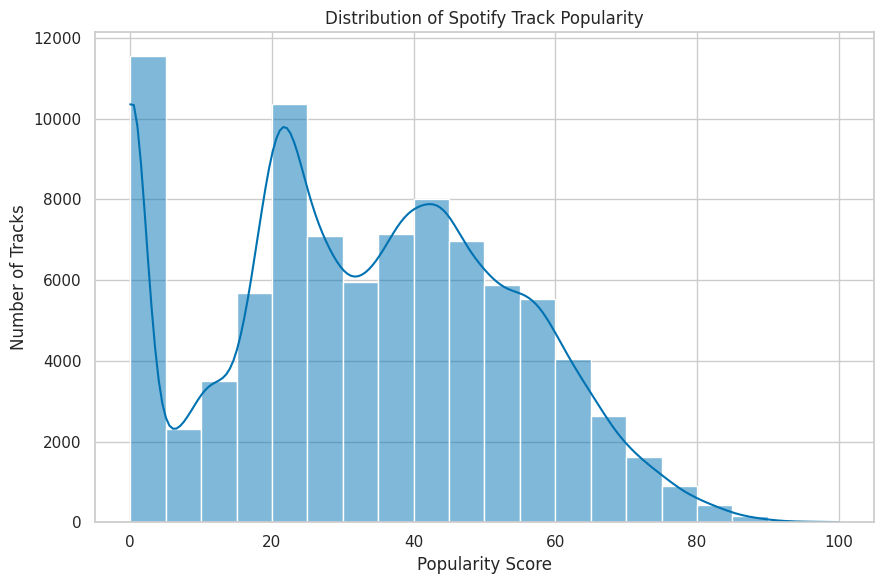

In [68]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.histplot(
    data=plot_data,
    x="popularity",
    bins=20,
    kde=True,
    color="#0072B2",
    ax=ax
)

ax.set_title("Distribution of Spotify Track Popularity")
ax.set_xlabel("Popularity Score")
ax.set_ylabel("Number of Tracks")

plt.tight_layout()
plt.savefig(
    "visualization_1_popularity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

figures.append(fig)
plt.show()

* Main finding: Most tracks have low-to-moderate popularity scores, while highly popular tracks are less common.

* Design rationale: A histogram was used to show how popularity scores are distributed across the dataset.

* Bias critique: Spotify popularity reflects listener activity and platform exposure, not necessarily music quality. The distribution may also be affected by how the dataset was collected.

### Visualization 2: Popularity by explicit status


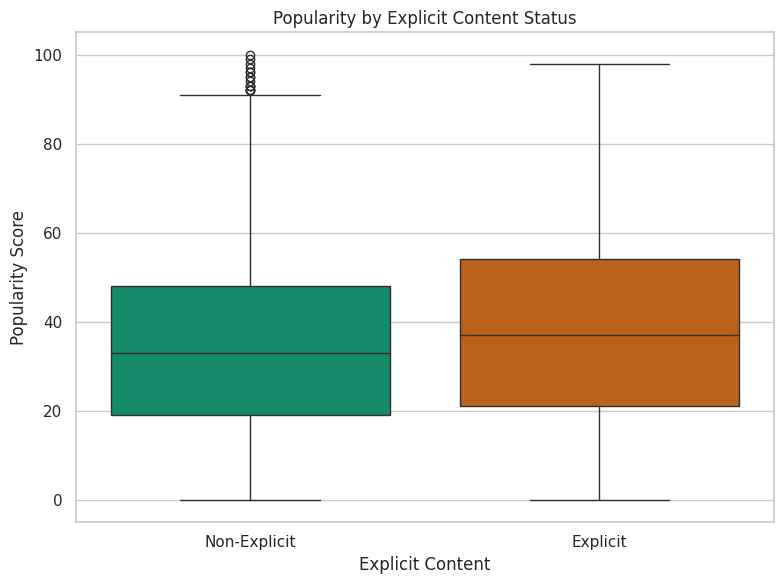

In [69]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.boxplot(
    data=plot_data,
    x="explicit",
    y="popularity",
    hue="explicit",
    palette=["#009E73", "#D55E00"],
    legend=False,
    ax=ax
)

ax.set_title("Popularity by Explicit Content Status")
ax.set_xlabel("Explicit Content")
ax.set_ylabel("Popularity Score")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Non-Explicit", "Explicit"])

plt.tight_layout()
plt.savefig(
    "visualization_2_popularity_by_explicit.png",
    dpi=300,
    bbox_inches="tight"
)

figures.append(fig)
plt.show()

* Main finding: Explicit tracks have a slightly higher median popularity than non-explicit tracks, supporting the results of the t-test.

* Design rationale: A box plot was used to compare the medians, spread, quartiles, and outliers of the two groups.

* Bias critique: This chart shows an association, not proof that explicit content causes higher popularity. Genre, artist, release year, and audience may also influence popularity.

### Visualization 3: Average popularity by genre

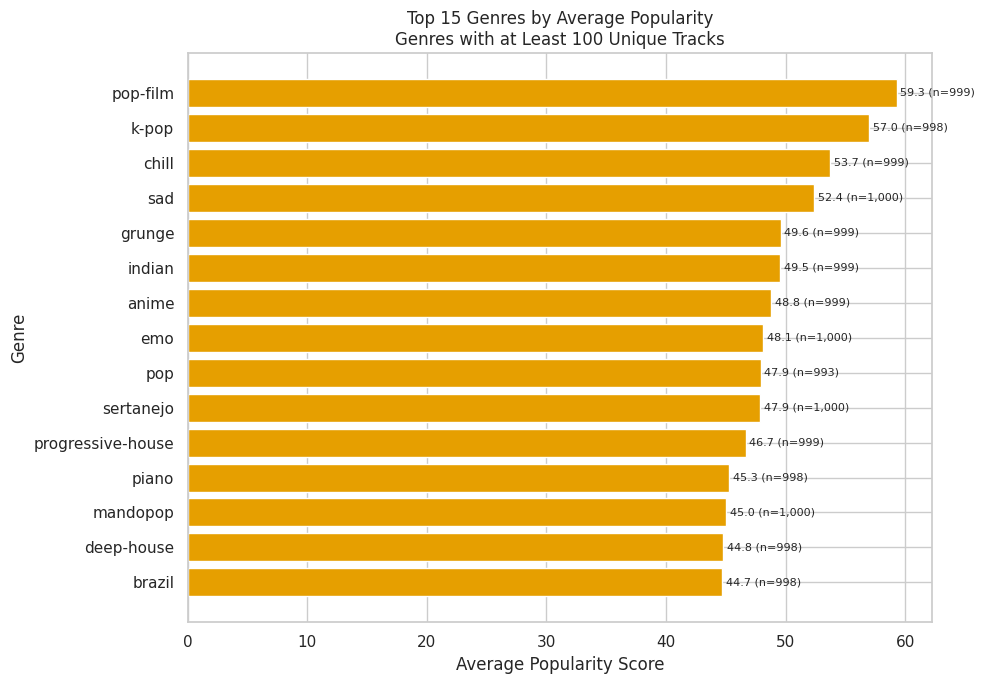

In [76]:
genre_summary = (
    df_clean
    .groupby("track_genre")
    .agg(
        average_popularity=("popularity", "mean"),
        track_count=("track_id", "nunique")
    )
    .query("track_count >= 100")
    .sort_values("average_popularity", ascending=False)
    .head(15)
    .sort_values("average_popularity")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    genre_summary["track_genre"],
    genre_summary["average_popularity"],
    color="#E69F00"
)

ax.set_title(
    "Top 15 Genres by Average Popularity\n"
    "Genres with at Least 100 Unique Tracks"
)
ax.set_xlabel("Average Popularity Score")
ax.set_ylabel("Genre")

# Add average popularity and track count labels
for bar, popularity, count in zip(
    bars,
    genre_summary["average_popularity"],
    genre_summary["track_count"]
):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{popularity:.1f} (n={count:,})",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.savefig(
    "visualization_3_popularity_by_genre.png",
    dpi=300,
    bbox_inches="tight"
)

figures.append(fig)
plt.show()

* Main finding: Pop-film and K-pop have the highest average popularity among the genres shown.

* Design rationale: A horizontal bar chart was used to make it easy to compare genre averages and read the genre names.

* Bias critique: The chart only includes genres with at least 100 unique tracks. Some tracks appear under multiple genres, and average popularity may hide differences within each genre.

### Visualization 4: Average audio features by musical mode

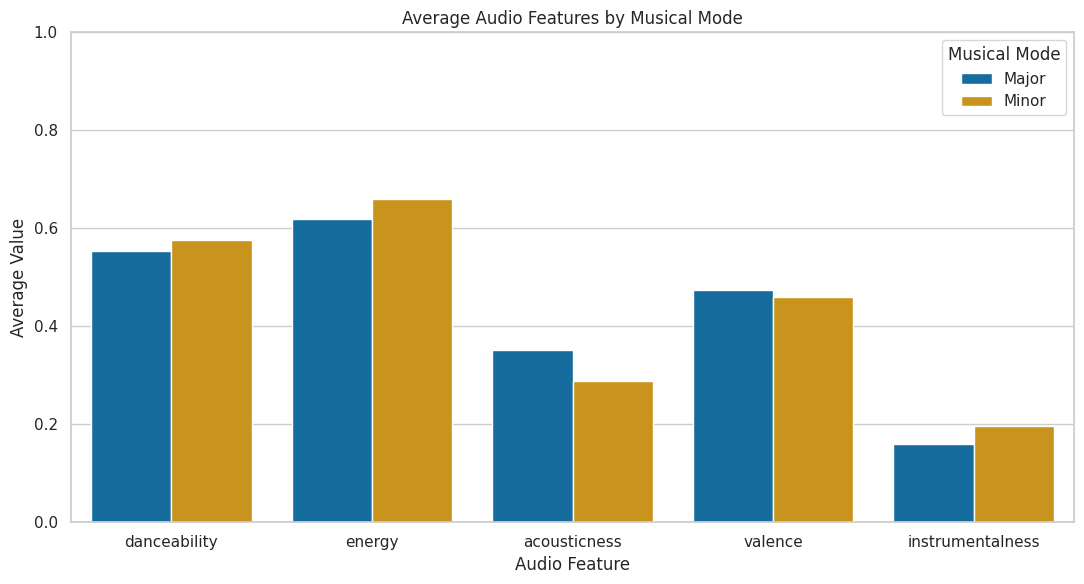

In [77]:
mode_data = unique_tracks.copy()

mode_data["mode_label"] = mode_data["mode"].map({
    1: "Major",
    0: "Minor"
})

audio_features = [
    "danceability",
    "energy",
    "acousticness",
    "valence",
    "instrumentalness"
]

mode_summary = (
    mode_data
    .groupby("mode_label")[audio_features]
    .mean()
    .reset_index()
)

mode_long = mode_summary.melt(
    id_vars="mode_label",
    var_name="Audio Feature",
    value_name="Average Value"
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=mode_long,
    x="Audio Feature",
    y="Average Value",
    hue="mode_label",
    palette=["#0072B2", "#E69F00"],
    ax=ax
)

ax.set_title("Average Audio Features by Musical Mode")
ax.set_xlabel("Audio Feature")
ax.set_ylabel("Average Value")
ax.set_ylim(0, 1)
ax.legend(title="Musical Mode")

plt.tight_layout()
plt.savefig(
    "visualization_4_audio_features_by_mode.png",
    dpi=300,
    bbox_inches="tight"
)

figures.append(fig)
plt.show()

* Main finding: Minor tracks have slightly higher average energy and danceability, while major tracks have slightly higher acousticness and valence.

* Design rationale: A grouped bar chart was used to compare multiple audio features between major and minor tracks.

* Bias critique: The chart compares group averages and hides individual variation. Musical mode does not necessarily cause differences in audio features, and genre may influence the results.

### Visualization 5: Track duration distribution

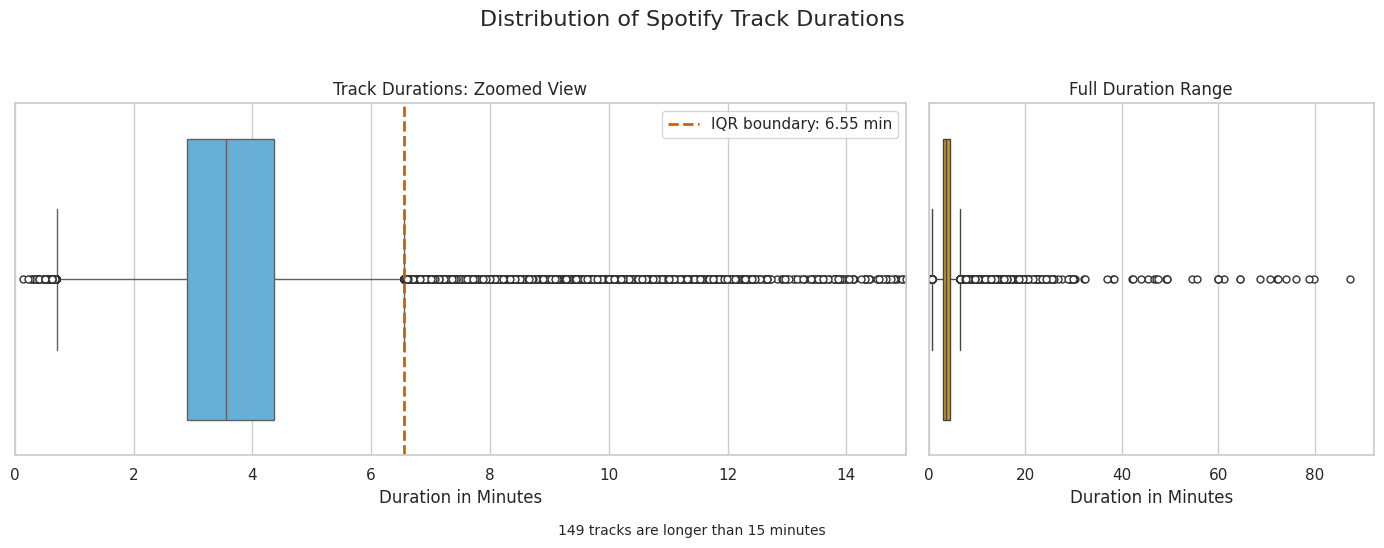

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

duration = df_clean["duration_min"].dropna()

# Calculate IQR outlier boundary
Q1 = duration.quantile(0.25)
Q3 = duration.quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# Count extreme tracks beyond the zoomed range
extreme_count = (duration > 15).sum()

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    gridspec_kw={"width_ratios": [2, 1]}
)

# Left: zoomed view
sns.boxplot(
    x=duration,
    color="#56B4E9",
    ax=axes[0],
    flierprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "#333333",
        "markersize": 5
    }
)

axes[0].set_xlim(0, 15)
axes[0].set_title("Track Durations: Zoomed View")
axes[0].set_xlabel("Duration in Minutes")
axes[0].axvline(
    upper_bound,
    color="#D55E00",
    linestyle="--",
    linewidth=2,
    label=f"IQR boundary: {upper_bound:.2f} min"
)
axes[0].legend()

# Right: full range
sns.boxplot(
    x=duration,
    color="#E69F00",
    ax=axes[1],
    flierprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "#333333",
        "markersize": 5
    }
)

axes[1].set_xlim(0, duration.max() + 5)
axes[1].set_title("Full Duration Range")
axes[1].set_xlabel("Duration in Minutes")

fig.suptitle(
    "Distribution of Spotify Track Durations",
    fontsize=16,
    y=1.03
)

fig.text(
    0.5,
    -0.02,
    f"{extreme_count:,} tracks are longer than 15 minutes",
    ha="center",
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "visualization_duration_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

* Main finding: Most tracks are approximately 3–4 minutes long, but the distribution is right-skewed because some tracks are much longer. The longest track is about 87 minutes, and 149 tracks are longer than 15 minutes.

* Design rationale: A two-panel box plot was used to show both the typical track-duration range and the extreme outliers. The zoomed view makes the main distribution easier to see, while the full-range view includes the longest tracks.

* Bias critique: The IQR method identifies statistical outliers, but these tracks may be legitimate extended recordings rather than errors. The two panels also use different x-axis scales, so viewers should compare the patterns carefully rather than the visual widths directly.

### Visualization 6: Correlation heatmap

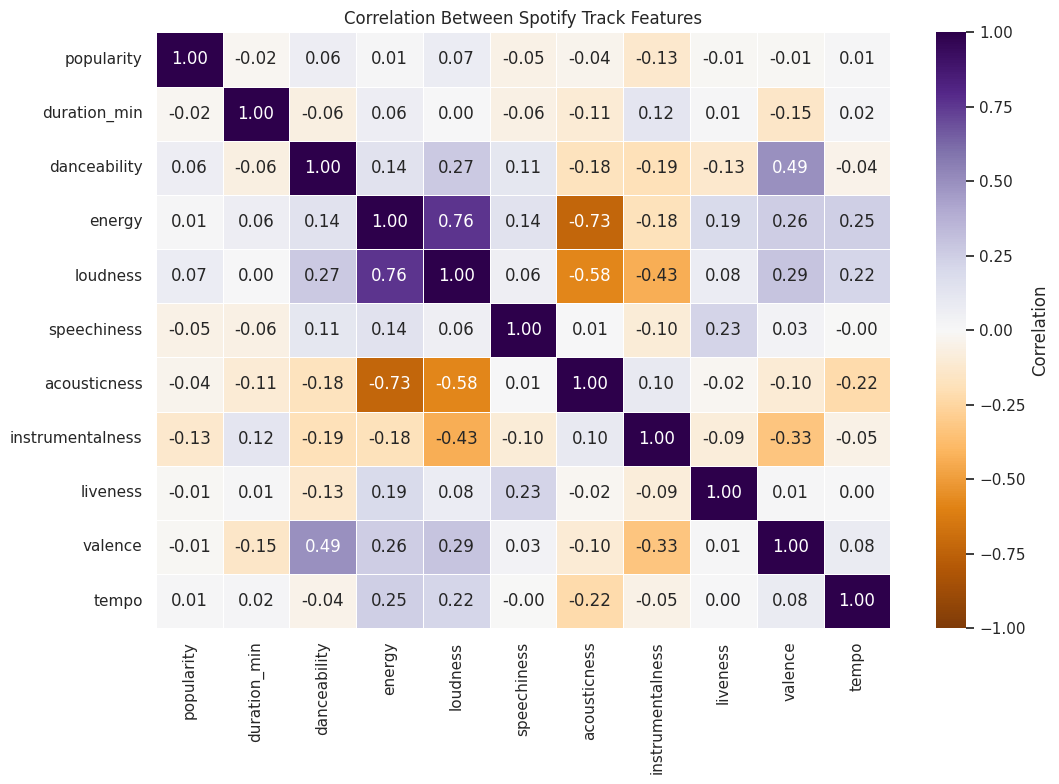

In [74]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="PuOr",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={
        "label": "Correlation"
    }
)

plt.title("Correlation Between Spotify Track Features")
plt.tight_layout()

plt.savefig(
    "visualization_5_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

*  Main finding: Energy and loudness have a strong positive correlation, while energy and acousticness have a strong negative correlation.

* Design rationale: A correlation heatmap was used to show the direction and strength of relationships among multiple numerical features.

* Bias critique: Correlation only measures linear relationships and does not prove causation. Weak correlations with popularity do not mean audio features have no effect on popularity.

Accessibility Check:

* The charts use high-contrast, colorblind-friendly colors, clear titles, labeled axes, readable legends, and direct data labels where appropriate
* The heatmap also displays the exact correlation values, so the reader does not have to rely only on color.

# **Milestone 3**